# 05-ROS2视觉识别、坐标转换与机械臂控制


## 1. 课程主线与资料范围

本篇对应《ROS视觉与控制.pdf》：先让机器从图像中找到物体，再把位置转换到机械臂的参考坐标系，最后理解机械臂如何根据目标位置计算关节角。

课件共55页，本篇逐页核对项目已保存的PDF页面预览：第1—54页为封面、目录、章节页与教学内容，第55页为品牌结束页。按原课顺序分为四部分：OpenCV与颜色识别、ROS视觉节点、坐标转换、正逆运动学。

图片保留课件原页码。课件主要给出概念、流程图和实验要求；下文完整Python示例、依赖配置、数值验证与必要的技术澄清均标为**工程补充**，不是课程源码包的转录。未读取视频全文或源码压缩包，未在ROS2、摄像头或机械臂上实跑。

前置知识沿用第02—04篇：Ubuntu 24.04、ROS2 Jazzy、工作空间与功能包、Topic发布订阅。命令在Ubuntu终端执行；本Notebook只包含Markdown阅读单元。

本篇要解决的三个问题是：图像里的目标在哪里？它相对于机器人在哪里？机器人应如何运动才能到达目标？这三个问题分别属于视觉、坐标转换和运动学。


## 2. OpenCV环境与图像矩阵

课件第4页先安装OpenCV并检查版本。独立OpenCV实验与ROS2环境分开准备，避免把ROS的系统依赖装进不兼容的Python环境。

**工程补充：**独立实验沿用项目的uv习惯，在Ubuntu创建实验目录；以下环境不用于运行`rclpy`或`cv_bridge`：

```bash
mkdir -p ~/opencv_lab
cd ~/opencv_lab
uv venv --python 3.12
uv pip install --python .venv/bin/python opencv-python numpy
.venv/bin/python -c 'import cv2; print(cv2.__version__)'
```

课件中的`pip install opencv-python`是同一安装目的；截图中的`exti()`应为`exit()`。打印版本号只说明这个解释器能导入OpenCV，不代表相机或GUI已可用。

第5—10页说明：数字图像是矩阵，彩色图像通常是`H × W × C`数组。以8位三通道图像为例，`H`为高度、`W`为宽度、`C=3`，每个通道的整数值为0—255。

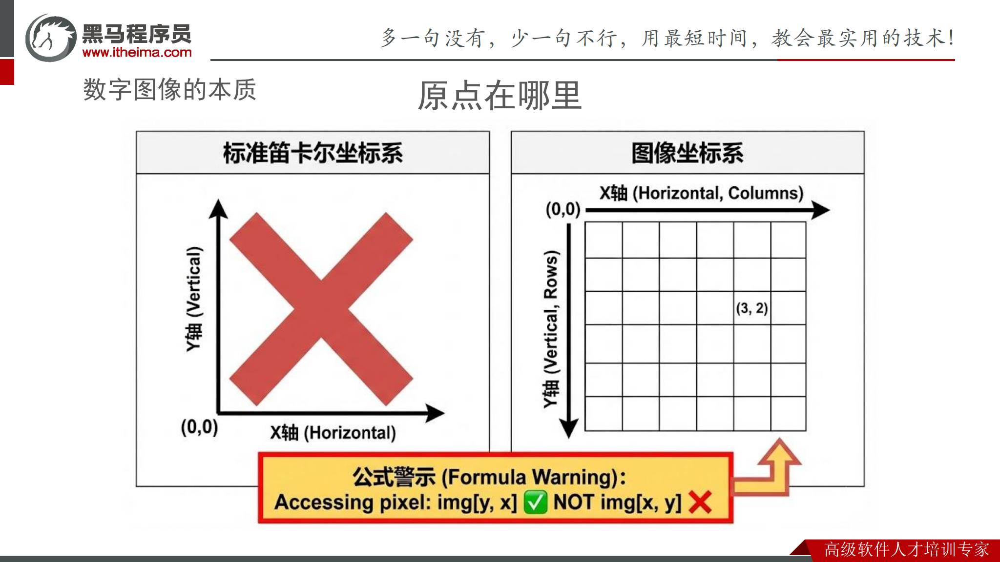

*原课件第7页：图像原点在左上，x向右、y向下；数组访问使用先行后列。*

| 想表达的量 | OpenCV / NumPy写法 |
|---|---|
| 图像形状 | `height, width, channels = image.shape` |
| 坐标为(x, y)的像素 | `image[y, x]` |
| 区域左上(x1, y1)、右下(x2, y2) | `image[y1:y2, x1:x2]`，右边界不包含 |
| 常见彩色图像类型 | `uint8`，三通道 |
| 灰度图 | 通常只有`H × W`，不能总按三维解包 |

图像坐标常写成`(u, v)`，以便与后面以米为单位的`(x, y, z)`区分。`u`对应列、`v`对应行。


## 3. BGR通道与图像、摄像头基础实验

课件第8—9页讲通道：OpenCV常见读取结果使用BGR顺序，像素`(255, 0, 0)`表示蓝色，`(0, 0, 255)`表示红色。接入需要RGB的显示库时，应显式转换。

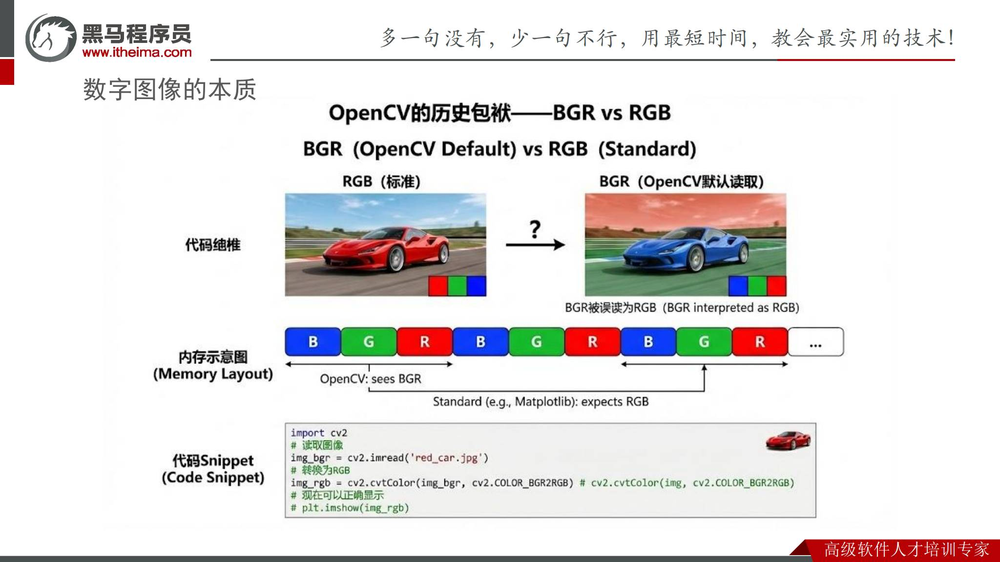

*原课件第9页：把BGR数据按RGB解释，会交换红、蓝的含义。*

第10页思考题：把G通道置零，不是把图像变成灰度图；剩下红、蓝通道，整体通常偏品红，具体效果取决于原图。操作应为`image[:, :, 1] = 0`。

第11页给出两项实验：创建图片并修改区域颜色；读取摄像头并修改区域颜色。下面是**工程补充示例**。在`~/opencv_lab/`保存为`image_basics.py`，用`.venv/bin/python image_basics.py`运行：

```python
import cv2
import numpy as np

canvas = np.zeros((240, 320, 3), dtype=np.uint8)
canvas[50:150, 80:200] = (0, 0, 255)
cv2.imshow('created image', canvas)
cv2.waitKey(0)
cv2.destroyAllWindows()

capture = cv2.VideoCapture(0)
try:
    if not capture.isOpened():
        raise RuntimeError('Cannot open camera 0')
    while True:
        ok, frame = capture.read()
        if not ok or frame is None:
            raise RuntimeError('Cannot read camera frame')
        frame[20:80, 20:100] = (0, 255, 0)
        cv2.imshow('camera', frame)
        if cv2.waitKey(1) & 0xFF == ord('q'):
            break
finally:
    capture.release()
    cv2.destroyAllWindows()
```

预期先出现黑底红色矩形，按键后进入相机画面，左上有绿色区域，按q退出。NumPy切片超出图像边界时会截断；直接访问单个越界像素则会报错。

`VideoCapture(0)`选择设备索引0，实际设备需核对；`read()`成功后才能处理图像。`imshow()`需要图形桌面，`waitKey()`还承担窗口事件处理。资源释放放在`finally`中，避免异常后设备仍被占用。


## 4. 为什么颜色识别要使用HSV

课件第12页提出问题：同一个红球从明亮处移到阴影里，RGB三个通道都可能变化。直接给R、G、B设置很窄的阈值，容易把同一物体漏掉。

第13—17页改用HSV，把颜色的几种属性分开：

| 分量 | 含义 | 调参时的作用 |
|---|---|---|
| H，Hue | 色相，如红、绿、蓝 | 限定目标颜色范围 |
| S，Saturation | 饱和度，颜色有多鲜明 | 排除接近灰白的区域 |
| V，Value | 明度 | 排除过暗区域，容许一定亮度变化 |

转换使用`cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)`。第18页的实验要求是读取相机、转换HSV、分离三个通道并查看结果，可用`h, s, v = cv2.split(hsv)`。

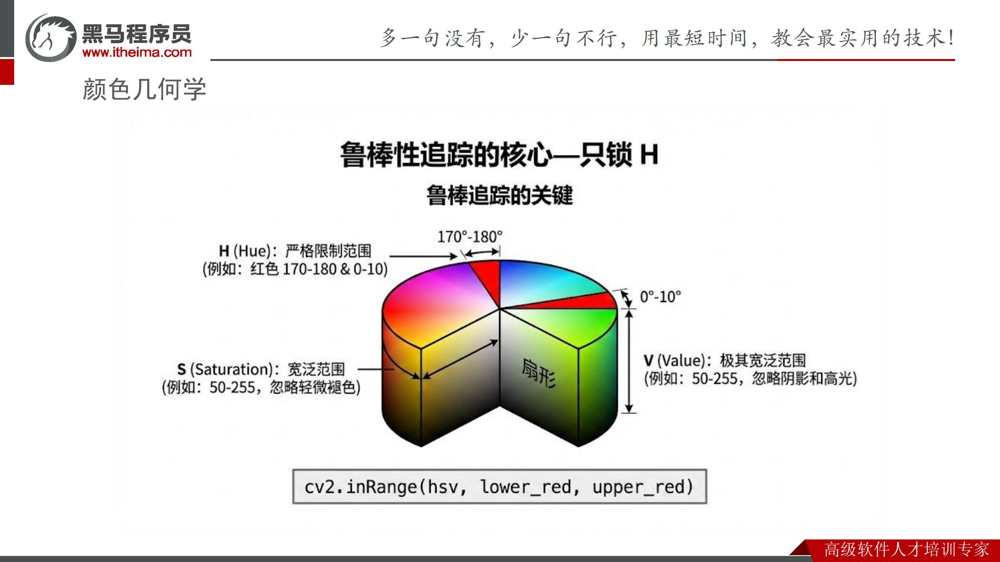

*原课件第16页：较严格地限制H，给S、V留出一定范围。*

**工程澄清：**本篇使用普通`COLOR_BGR2HSV`与`uint8`输入，H实际取值为0—179，S、V为0—255。课件图中将H范围简写为0—180；它不是0—360的直接角度，也不是所有HSV数据格式的通用范围。

红色横跨H的首尾，通常需要两段阈值，例如H为0—10或170—179，再将两个掩膜合并。不能写成“下限170、上限10”的单段区间。

课件“只锁H”的意思是重点控制色相，仍要给S、V设置合理下限。低饱和度、极暗、高光、自动白平衡或彩色光源都可能让H不稳定；HSV减轻颜色与亮度混在一起的问题，不能保证完全不受光照影响。


## 5. 掩膜与形态学：从颜色范围到干净区域

课件第19—24页把颜色筛选结果变成掩膜（Mask）。`cv2.inRange(hsv, lower, upper)`检查每个像素的各通道是否落在范围内，得到单通道图：满足条件为255，不满足为0。它表达“这个像素是否属于候选目标”，不是物体类别识别的概率。

实际掩膜会有散点、空洞和边缘毛刺。形态学使用一个小矩阵，即结构元素或核，对邻域作处理。

| 操作 | 对白色前景的影响 | 常见用途与限制 |
|---|---|---|
| 腐蚀，`erode` | 收缩白色区域 | 去小白点，也会削掉细小目标 |
| 膨胀，`dilate` | 扩大白色区域 | 连接断裂，也可能合并相邻目标 |
| 开运算，`MORPH_OPEN` | 先腐蚀，再膨胀 | 去除小白色噪声，尽量保留较大区域 |

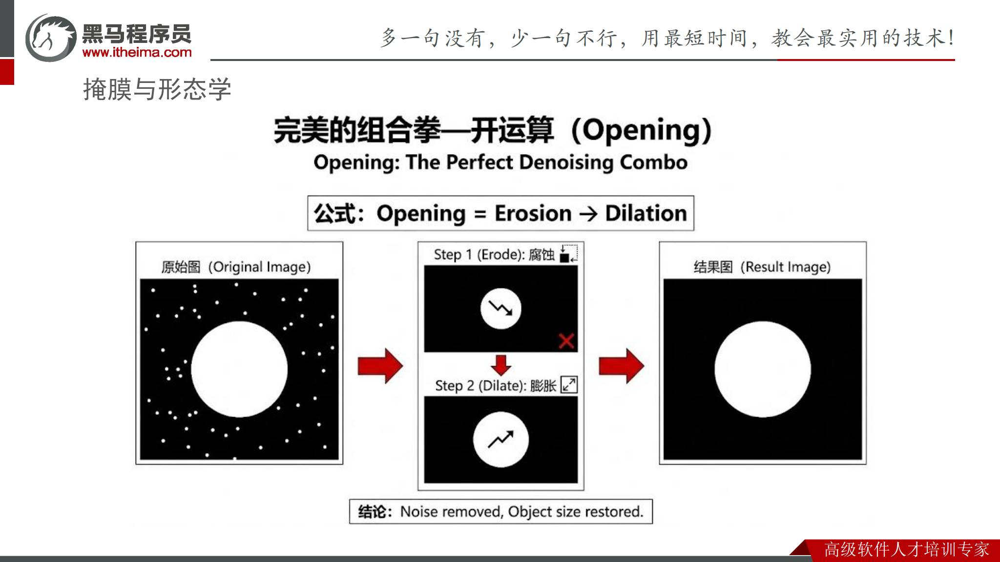

*原课件第23页：先腐蚀去掉散点，再膨胀恢复主要区域。*

**工程补充：**开运算不会无损恢复原形，小于核的结构可能消失。它也不是专门填补黑色小孔的操作，不能把“膨胀可扩张白色”理解为“开运算一定填孔”。核越大、重复次数越多，对细节的影响越大。

第24页实验按顺序查看：原图 → 原始Mask → 去噪Mask。先确认颜色阈值，再调整核；不要用很大的核掩盖颜色阈值本身的问题。


## 6. 轮廓、矩与目标中心

课件第25—28页要把一团白色区域变成一个可传递的坐标。直觉是求所有前景位置的平均值，即几何中心或质心。

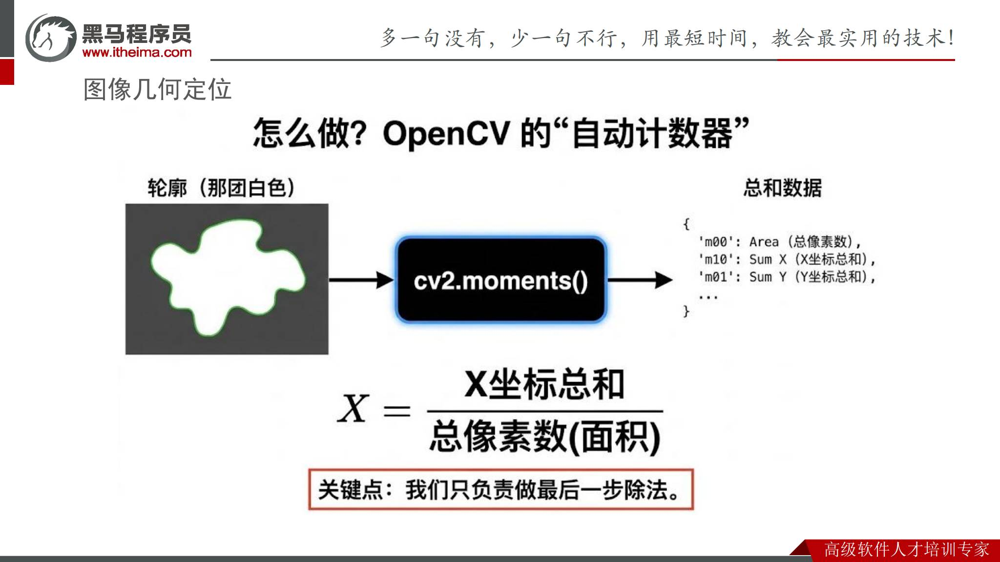

*原课件第27页：OpenCV计算矩，使用一阶矩除以零阶矩得到中心。*

对于区域的矩：

\[
u_c=\frac{m_{10}}{m_{00}},\qquad
v_c=\frac{m_{01}}{m_{00}}.
\]

`m00`为零阶矩，`m10`反映水平方向的一阶矩，`m01`反映竖直方向的一阶矩。使用前先检查`m00`非零。

**工程澄清：**`cv2.moments(mask, binaryImage=True)`把非零像素按1计算，`m00`是前景像素数；`cv2.moments(contour)`按轮廓围成的几何区域计算面积矩，面积不一定等于离散像素个数。两者的质心公式相同，但不要混用“像素计数”和“轮廓面积”的解释。

如果图里有两个红色物体，直接求整张Mask的中心，可能得到两个物体之间的空位置。常用教学策略是：先找外轮廓，过滤小区域，选最大轮廓，再计算它的中心。这个策略假设“最大的红色区域就是目标”，背景有大块红色时会选错。

第28页要求框选物体并显示实时坐标。框可以使用`cv2.boundingRect()`，中心使用矩；矩形中心与区域质心不一定相同。识别不到目标时应明确返回“无目标”，不要把`(0, 0)`当作缺失值。


## 7. OpenCV实验：红色目标框选与实时坐标

以下为完成课件第18、24、28页实验的**工程补充**，不涉及机械臂运动。在`~/opencv_lab/`保存为`red_tracker.py`，运行`.venv/bin/python red_tracker.py`。

检测函数与相机循环分开，后面接入ROS2时可以复用同一算法。阈值和面积下限只是实验起点，需要根据实际画面调整。

```python
import cv2
import numpy as np


def detect_red(frame, min_area=300.0):
    hsv = cv2.cvtColor(frame, cv2.COLOR_BGR2HSV)
    low_red = cv2.inRange(
        hsv, np.array([0, 80, 50], dtype=np.uint8),
        np.array([10, 255, 255], dtype=np.uint8))
    high_red = cv2.inRange(
        hsv, np.array([170, 80, 50], dtype=np.uint8),
        np.array([179, 255, 255], dtype=np.uint8))
    raw_mask = cv2.bitwise_or(low_red, high_red)
    kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (5, 5))
    mask = cv2.morphologyEx(raw_mask, cv2.MORPH_OPEN, kernel)
    contours, _ = cv2.findContours(
        mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    candidates = [c for c in contours if cv2.contourArea(c) >= min_area]
    if not candidates:
        return mask, None
    contour = max(candidates, key=cv2.contourArea)
    moments = cv2.moments(contour)
    if moments['m00'] <= 0.0:
        return mask, None
    center = (moments['m10'] / moments['m00'],
              moments['m01'] / moments['m00'])
    box = cv2.boundingRect(contour)
    return mask, (center, box)


def main():
    capture = cv2.VideoCapture(0)
    try:
        if not capture.isOpened():
            raise RuntimeError('Cannot open camera 0')
        while True:
            ok, frame = capture.read()
            if not ok or frame is None:
                raise RuntimeError('Cannot read camera frame')
            mask, result = detect_red(frame)
            if result is not None:
                (u, v), (x, y, width, height) = result
                cv2.rectangle(frame, (x, y),
                              (x + width, y + height), (0, 255, 0), 2)
                cv2.circle(frame, (round(u), round(v)), 5, (0, 255, 255), -1)
                label = f'u={u:.1f}, v={v:.1f}'
            else:
                label = 'No target'
            cv2.putText(frame, label, (10, 25), cv2.FONT_HERSHEY_SIMPLEX,
                        0.6, (0, 255, 0), 2)
            cv2.imshow('target', frame)
            cv2.imshow('mask', mask)
            if cv2.waitKey(1) & 0xFF == ord('q'):
                break
    finally:
        capture.release()
        cv2.destroyAllWindows()


if __name__ == '__main__':
    main()
```

验证时先用单个红色物体与简单背景：向右移动，`u`应增大；向下移动，`v`应增大；移出画面，应显示`No target`。再加入小红点或第二个红色物体，观察去噪与“选最大区域”的效果。

颜色阈值识别只说明外观满足设定条件；它不会自动区分红球、红盒子与红色背景，也未建立跨帧目标身份。


## 8. 把视觉脚本拆成ROS2数据流

课件第29—30页从独立脚本转到ROS视觉子系统：相机驱动负责采图，视觉节点订阅图像并处理，其他节点使用识别结果。

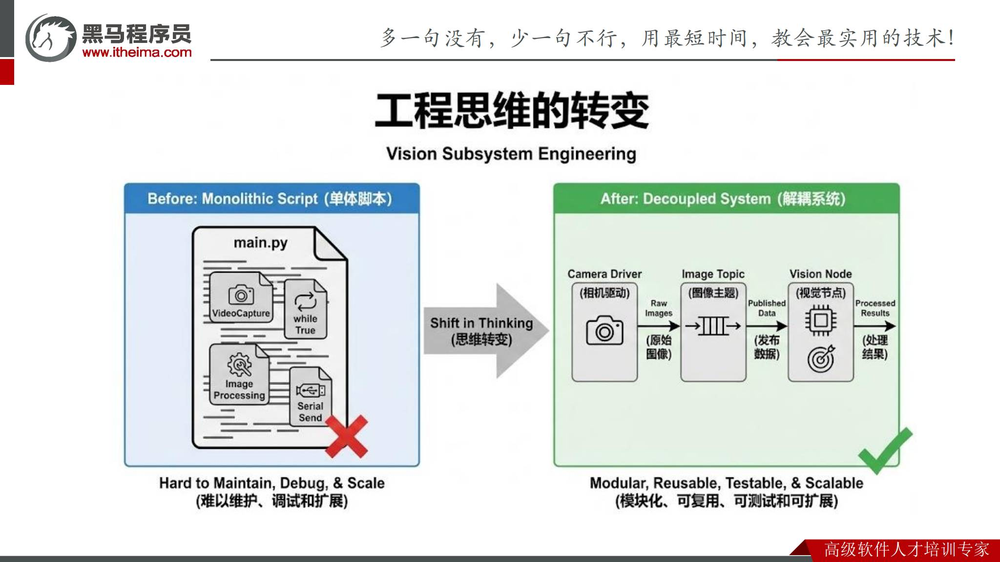

*原课件第30页：将相机采集、图像传输与视觉处理分开。*

```text
相机驱动 → 图像Topic → 视觉识别节点 → 目标位置Topic → 后续业务节点
```

课件第33—35页逐步增加需求：显示原图 → 根据HSV框选目标并显示坐标 → 将目标位置发布给其他节点。显示窗口便于人调试，位置消息才是后续模块的输入接口。

与第04篇相同，应先约定消息语义：位置是像素还是米、在哪个坐标系中、何时采集、当前有没有目标。一个节点直接采相机、识别颜色、发串口并控制机械臂，会让这些问题混在一起。


## 9. ROS2摄像头驱动与图像查看

课件第31页先用Cheese测试虚拟机相机，再安装`usb_cam`，启动驱动并用`rqt_image_view`观察图像。

在Ubuntu终端执行，ROS2节点使用系统Python环境；不要激活前面独立OpenCV实验的虚拟环境：

```bash
source /opt/ros/jazzy/setup.bash
sudo apt update
sudo apt install cheese ros-jazzy-usb-cam ros-jazzy-rqt-image-view \
  ros-jazzy-cv-bridge python3-opencv python3-numpy
cheese
```

在虚拟机中把摄像头连接给Ubuntu，确认能看到`/dev/video*`设备。课件提示配置USB 3.1，实际还需匹配虚拟机软件、控制器与相机支持情况。Cheese能看到画面后先退出，让设备释放，再运行：

```bash
ros2 run usb_cam usb_cam_node_exe
```

另开已加载ROS环境的终端查看：

```bash
ros2 topic list -t
ros2 run rqt_image_view rqt_image_view
```

在界面选择驱动实际发布的图像话题，常见为`/image_raw`。**工程补充：**后续先确认名称与类型，再检查接口和频率：

```bash
ros2 interface show sensor_msgs/msg/Image
ros2 topic info /image_raw --verbose
ros2 topic hz /image_raw
```

设备路径、分辨率、像素格式等配置需与相机支持能力一致，可通过驱动的参数文件和日志核对。不要同时启动多个驱动争抢同一设备。

预期是驱动有图像发布、`rqt_image_view`能显示画面。仅有Topic名称不能证明相机正在产出有效图像。


## 10. CvBridge：连接ROS图像消息与OpenCV数组

课件第32页解释`cv_bridge`，第33页把它用于原图显示节点。

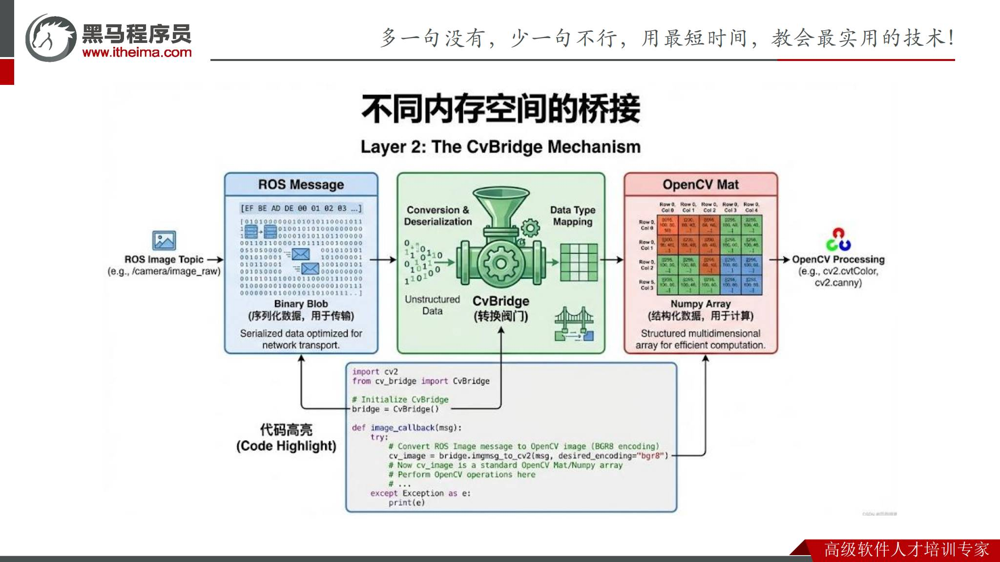

*原课件第32页：将ROS图像消息转成OpenCV可处理的矩阵数据。*

`sensor_msgs/msg/Image`不只是像素数组，还包含`header`、`height`、`width`、`encoding`、`step`、`is_bigendian`和`data`。其中`step`表示每行数据的字节数；不能假设所有来源都是紧密排列的三通道BGR。

**工程补充片段：**在订阅`Image`的节点中初始化`bridge = CvBridge()`，回调中使用：

```python
from cv_bridge import CvBridge

bridge = CvBridge()


def decode_bgr(image_message):
    return bridge.imgmsg_to_cv2(image_message, desired_encoding='bgr8')
```

`bgr8`明确要求8位BGR结果，方便复用前面的颜色算法。直接使用`passthrough`会保留原编码；如果原消息是`rgb8`，却按BGR计算HSV，识别颜色就会出错。

转换异常应记录并跳过该帧。课件“不同内存空间的桥接”是帮助理解格式转换的类比；`cv_bridge`不保证整个传输链零拷贝，ROS图像消息也不是没有结构的数据。

第33页的原图显示还需`imshow()`与`waitKey()`；如果只需要供其他节点使用，可以发布处理结果，不必依赖GUI。


## 11. ROS2识别节点：订阅图像、发布像素位置

课件第34页在图像节点里加入HSV与形态学处理，第35页进一步发布物体位置。

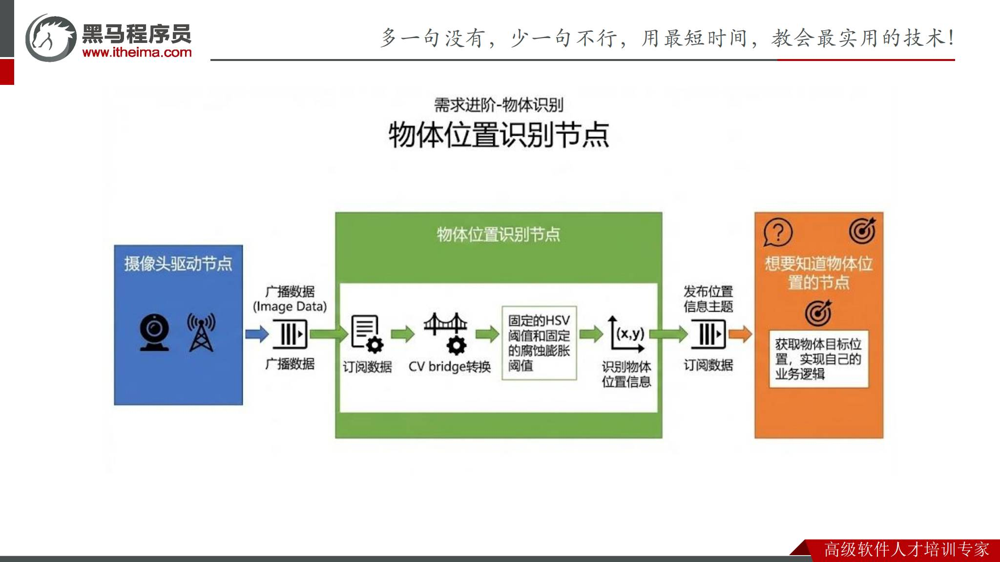

*原课件第35页：视觉节点发布位置，让其他业务节点独立使用。*

以下为**工程补充**。先在Ubuntu创建包：

```bash
source /opt/ros/jazzy/setup.bash
cd ~/dev_ws/src
ros2 pkg create vision_demo --build-type ament_python \
  --dependencies rclpy sensor_msgs cv_bridge std_msgs
```

在`~/dev_ws/src/vision_demo/vision_demo/`中创建`red_detector.py`，仅复制第7节的`detect_red()`及其`cv2`、`numpy`导入，不复制相机循环。相机由`usb_cam`统一管理。

课件未给出此处的具体消息定义。为明确区分像素与空间点，在包外层`~/dev_ws/src/`创建独立接口包：

```bash
ros2 pkg create vision_interfaces --build-type ament_cmake
mkdir -p ~/dev_ws/src/vision_interfaces/msg
```

保存`~/dev_ws/src/vision_interfaces/msg/PixelTarget.msg`：

```text
std_msgs/Header header
bool detected
float64 u
float64 v
```

`header`沿用原图的采集时间与参考帧；`u`、`v`为该图像中的像素坐标，**不是该帧下以米表示的三维位置**。`detected=false`时忽略坐标字段。分辨率或裁剪发生变化时，定位标定也必须对应同一图像几何。

将接口包的`CMakeLists.txt`整理为：

```cmake
cmake_minimum_required(VERSION 3.8)
project(vision_interfaces)

find_package(ament_cmake REQUIRED)
find_package(rosidl_default_generators REQUIRED)
find_package(std_msgs REQUIRED)

rosidl_generate_interfaces(${PROJECT_NAME}
  "msg/PixelTarget.msg"
  DEPENDENCIES std_msgs
)

ament_export_dependencies(rosidl_default_runtime)
ament_package()
```

在接口包`package.xml`的`<package>`内部补充以下依赖，保留已有`ament_cmake`构建依赖与导出项：

```xml
<build_depend>rosidl_default_generators</build_depend>
<exec_depend>rosidl_default_runtime</exec_depend>
<depend>std_msgs</depend>
<member_of_group>rosidl_interface_packages</member_of_group>
```

在`vision_demo/package.xml`内部补充：

```xml
<exec_depend>vision_interfaces</exec_depend>
<exec_depend>python3-opencv</exec_depend>
<exec_depend>python3-numpy</exec_depend>
```

保存`~/dev_ws/src/vision_demo/vision_demo/red_target_node.py`：

```python
import rclpy
from rclpy.node import Node
from rclpy.qos import qos_profile_sensor_data
from sensor_msgs.msg import Image
from cv_bridge import CvBridge, CvBridgeError
from vision_interfaces.msg import PixelTarget
from vision_demo.red_detector import detect_red


class RedTargetNode(Node):
    def __init__(self):
        super().__init__('red_target_node')
        self.declare_parameter('image_topic', '/image_raw')
        topic = self.get_parameter('image_topic').value
        self.bridge = CvBridge()
        self.publisher = self.create_publisher(PixelTarget, '/target/pixel', 10)
        self.subscription = self.create_subscription(
            Image, topic, self.on_image, qos_profile_sensor_data)

    def on_image(self, image):
        target = PixelTarget()
        target.header = image.header
        target.detected = False
        try:
            frame = self.bridge.imgmsg_to_cv2(image, desired_encoding='bgr8')
        except CvBridgeError as error:
            self.get_logger().warning(f'Image conversion failed: {error}')
            self.publisher.publish(target)
            return
        _, result = detect_red(frame)
        if result is not None:
            (target.u, target.v), _ = result
            target.detected = True
        self.publisher.publish(target)


def main(args=None):
    rclpy.init(args=args)
    node = RedTargetNode()
    try:
        rclpy.spin(node)
    except KeyboardInterrupt:
        pass
    finally:
        node.destroy_node()
        if rclpy.ok():
            rclpy.shutdown()
```

使用传感器QoS订阅图像，具体兼容性仍通过`topic info --verbose`核对。每处理一帧都发布“发现/未发现”，让下游区分目标移出画面与正常检测。

在`vision_demo/setup.py`已有`console_scripts`列表中增加：

```python
'red_target = vision_demo.red_target_node:main',
```

在Ubuntu工作空间构建、加载并运行：

```bash
cd ~/dev_ws
rosdep install --from-paths src --ignore-src -r -y
colcon build --packages-up-to vision_demo --symlink-install
source install/setup.bash
ros2 interface show vision_interfaces/msg/PixelTarget
ros2 run vision_demo red_target --ros-args -p image_topic:=/image_raw
```

另开已加载环境的终端执行`ros2 topic echo /target/pixel`，检查目标出现时`detected=true`、消失时为`false`，并核对移动方向与像素值变化。

如果相机或识别进程停止，下游就收不到消息；因此控制端仍需独立检查超时。当前节点只输出像素结果，不会向机械臂发动作指令。


## 12. 从像素到物理位置：TF2之前还缺什么

课件第36—38页引入固定在机械臂外部的相机，即Eye-to-Hand场景，并用桌面平面简化抓取问题：相机看到的是像素，机械臂需要的是物理空间位置。

这中间实际有两步：

```text
图像像素(u, v)
    ↓ 相机标定、深度或已知平面约束
相机/工作平面下的物理点，单位米
    ↓ 已知坐标系之间的刚体变换，TF2
机械臂基座下的物理点，单位米
```

**工程澄清：TF2只负责第二步，不能把像素自动变成米。**一个单目像素通常对应一条空间射线，缺少距离时无法唯一确定三维点。把`u=200、v=300`直接写入以米为单位的`PointStamped`，即使TF查询成功，结果也没有正确的物理意义。

课程将高度忽略以解释二维映射；实际桌面实验仍需标定像素与该平面的关系。例如已知平面可标定单应关系，且应使用足够的对应点、独立验证点并考虑镜头畸变。它只适用于相应平面与相机安装条件，物体高度变化会产生误差。

深度相机则还要核对深度单位、图像对齐和相机内参。课件没有给出完整的标定数据与像素定位实现，本篇保留这个前置条件，不填入虚构的比例系数或真实抓取坐标。

后面的TF2示例全部假设：输入已经是**米制空间点**，并且它所在的参考帧已明确。


## 13. 坐标系、父子关系与平移

课件第39页先问“谁是原点”：机械臂基座定义为`base_link`，相机参考帧为`camera_link`，通过父子关系描述安装位置。

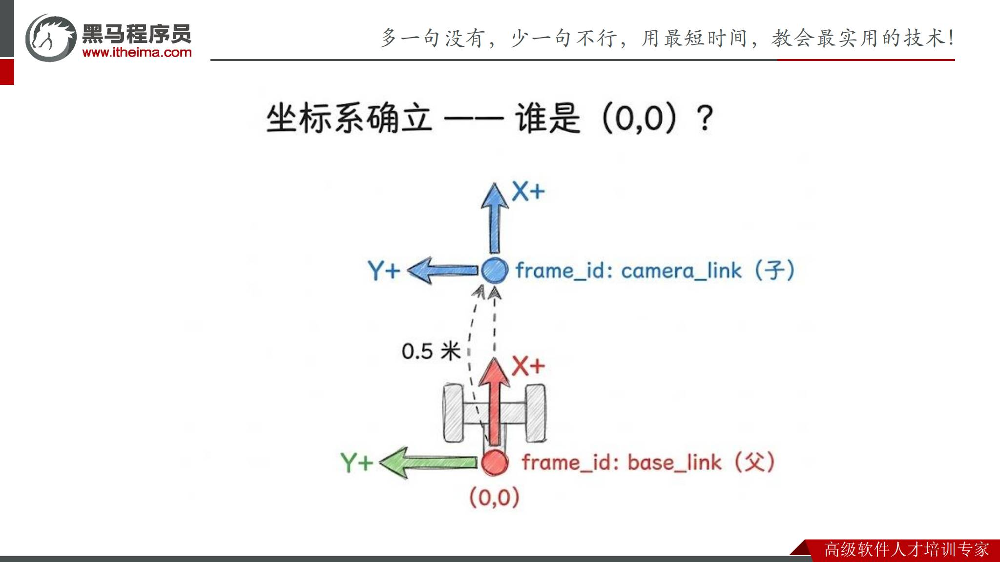

*原课件第39页：用父帧base_link与子帧camera_link表达安装关系。*

课件第40页先考虑两帧方向一致、仅平移的例子：相机原点在基座的`(0.5, 0)`米，目标在相机帧中为`(0.1, 0.1)`米，那么：

\[
p_{base}=p_{camera}+t=(0.6,\ 0.1)\ \text{m}.
\]

这里相加的前提是两组坐标已经使用相同单位，且坐标轴方向一致。旋转不为零时不能只加安装位置。

**工程补充：**ROS常用机体坐标约定为右手系：x前、y左、z上；相机光学帧通常为x右、y下、z前。`camera_link`与`camera_optical_frame`可能是不同帧，不能因为名字都有camera就当成同一方向。

安装位置和朝向来自实际测量或标定。`frame_id`是数据的参考系声明，改一个字符串不会改变数值的真实含义。


## 14. 旋转与TF2静态变换

课件第41页解释方向不一致的问题：相机中的x增加，可能对应基座中的y减少。第42页用TF2发布安装变换。

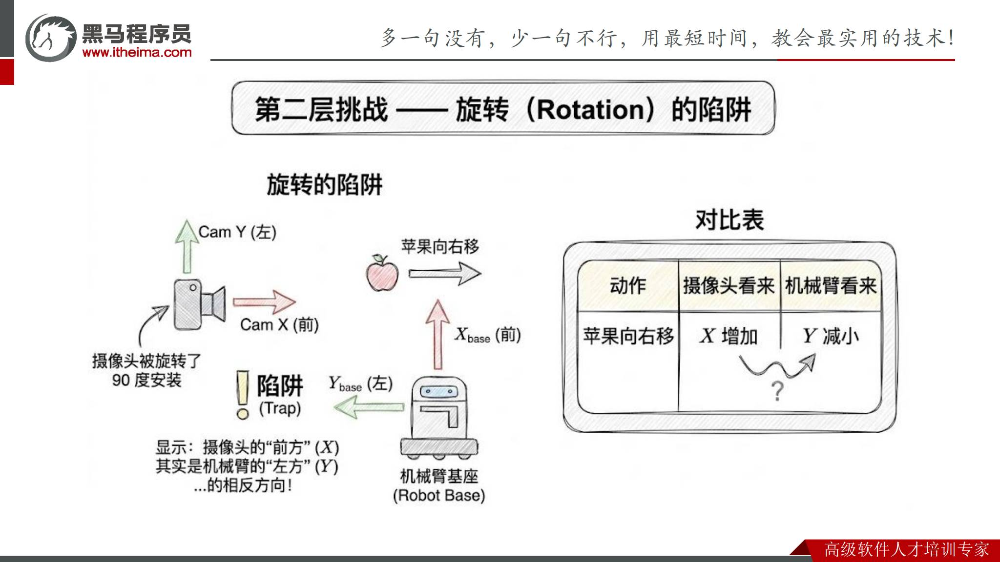

*原课件第41页：相机朝向改变后，不能继续逐分量相加。*

在平面内，定义`theta`为子帧相对于父帧绕+z的转角，子帧点转换到父帧的公式为：

\[
\begin{aligned}
x_b&=\cos\theta\,x_c-\sin\theta\,y_c+t_x,\\
y_b&=\sin\theta\,x_c+\cos\theta\,y_c+t_y.
\end{aligned}
\]

**课件差异说明：**第41页画出`+x_camera → -y_base`的方向关系；按上面的右手坐标约定，这对应`theta=-π/2`。第42页位置参数示例却出现正的`1.57`，不能把两页当成同一组安装参数直接照抄。下面明确选择第41页的方向，并使用命名参数消除位置参数的顺序歧义。

以下为**工程补充教学变换**，单位为米与弧度，仅用于理解，不是某台实际设备的标定结果。已存在同名父子变换时不要重复发布：

```bash
source /opt/ros/jazzy/setup.bash
ros2 run tf2_ros static_transform_publisher \
  --x 0.5 --y 0.0 --z 0.0 \
  --roll 0.0 --pitch 0.0 --yaw -1.5707963267948966 \
  --frame-id base_link --child-frame-id camera_link
```

另开终端查询：

```bash
source /opt/ros/jazzy/setup.bash
ros2 run tf2_ros tf2_echo base_link camera_link
```

预期平移为`(0.5, 0, 0)`，旋转等价于绕z的-90°；四元数整体取反仍表示相同旋转。此变换把相机点`(0.1, 0.1, 0)`转换为基座点`(0.6, -0.1, 0)`，与上一节无旋转结果的y不同。

固定安装关系使用静态变换；机械臂关节随时间变化的关系需要动态更新。TF树应保持连通、每个子帧有唯一父帧，避免多个节点为同一关系发布互相冲突的数据。


## 15. TF2转换点：来源帧、目标帧与时间

课件第43页把目标识别、坐标转换和运动节点连起来。TF数据表达参考系关系，业务消息表达一次目标观测；两者都需要正确的方向和时间。

**工程补充片段：**下面展示在现有`rclpy`节点里处理已完成物理定位的`PointStamped`。它不是接收`PixelTarget`的像素转换程序。需在`vision_demo/package.xml`中声明`geometry_msgs`、`tf2_ros`、`tf2_geometry_msgs`执行依赖，并构建、加载环境。

```python
from geometry_msgs.msg import PointStamped
from tf2_ros import Buffer, TransformListener, TransformException
import tf2_geometry_msgs  # 注册PointStamped等几何类型的转换


class TargetTransformNode(Node):
    def __init__(self):
        super().__init__('target_transform_node')
        self.buffer = Buffer()
        self.listener = TransformListener(self.buffer, self)
        self.publisher = self.create_publisher(
            PointStamped, '/target/base_point', 10)
        self.subscription = self.create_subscription(
            PointStamped, '/target/camera_point', self.on_point, 10)

    def on_point(self, point):
        if not point.header.frame_id:
            self.get_logger().warning('Target has no source frame')
            return
        try:
            in_base = self.buffer.transform(point, 'base_link')
        except TransformException as error:
            self.get_logger().warning(f'Target transform unavailable: {error}')
            return
        self.publisher.publish(in_base)
```

片段依赖第11节已有的`Node`导入和节点启动模式；这里省略重复的`rclpy.init()`、`spin()`与关闭代码，不能把片段直接当成已注册的可执行程序。

`point.header.frame_id`是来源帧，`'base_link'`是目标帧。在TF API中，`lookup_transform(target_frame, source_frame, time)`得到将source数据表达在target中的变换，不能根据英文阅读顺序反过来使用。

应保留原观测时间，查询该时刻可用的变换。零时间戳通常请求最新变换，不等于与图像严格同步。示例在变换不可用时跳过，不在单线程图像回调里长时间阻塞等待；如需等待后重试，应结合缓存或消息过滤组织。

TF2不会判断目标是否仍存在、测量是否过期或数值是否可信。控制端使用转换结果前，还需按业务检查有限值、时间、工作空间与有效性。尤其不能在识别失败后继续无限使用上次目标。


## 16. 运动学、URDF与父子变换链

课件第44—48页从“目标在哪里”转向“机械臂怎么摆”。运动学研究几何运动关系；质量、力、力矩和动力学控制属于另一个层面。

| 问题 | 输入 | 输出 |
|---|---|---|
| 正运动学，FK | 关节位置/角度与机器人模型 | 末端位置与姿态 |
| 逆运动学，IK | 目标末端位姿与机器人模型 | 满足目标的关节解 |

第47页用机器人骨架说明URDF：`link`描述连杆，`joint`描述相邻连杆的连接与相对运动，包含父子关系、安装原点、运动轴和必要的限制。URDF是描述文件，不能仅凭一个URDF自动驱动电机。

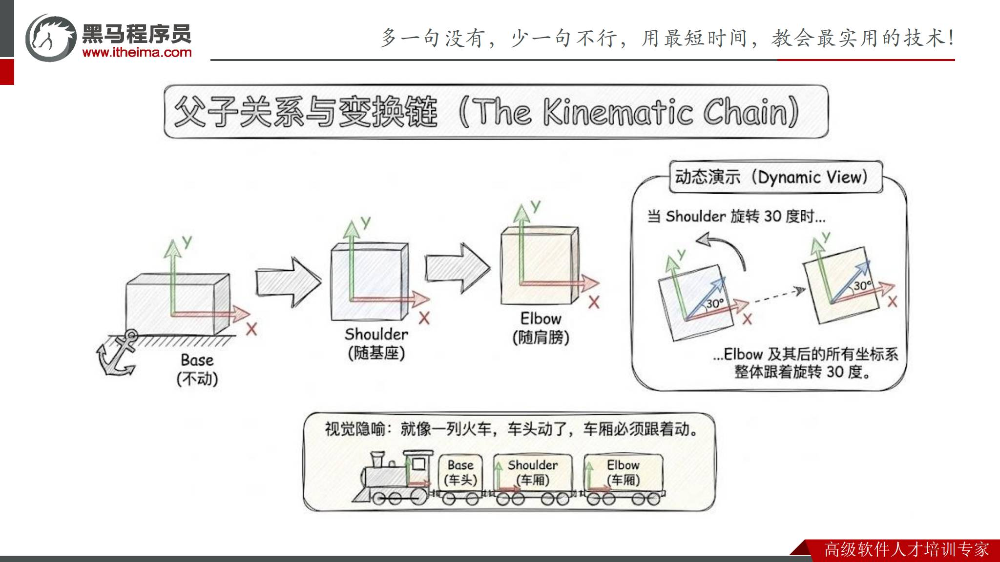

*原课件第48页：上游关节改变时，其后的连杆与参考系都会随之改变。*

第48页的关键是变换链：基座 → 肩 → 肘 → 腕 → 末端。对于串联机械臂，末端变换由每段父子变换相乘得到：

\[
{}^{base}T_{tool}={}^{base}T_1\,{}^1T_2\cdots{}^{n-1}T_{tool}.
\]

矩阵乘法有顺序，不能随意交换。每个关节的旋转要按模型定义的局部轴和零位解释。

**工程补充：**`robot_state_publisher`可根据URDF和关节状态发布连杆TF，但它不负责自动求IK，也不等同于轨迹控制器。URDF、TF、求解器和硬件驱动各自承担不同职责。


## 17. 正运动学：在同一参考系中叠加连杆

课件第49页把正解解释为向量叠加，第52页用多个关节动作展示末端位置随整条链变化。向量相加前必须先把每段连杆表达在同一坐标系中。

下面是**工程补充的二维二连杆模型**，用于解释相对关节角：两根刚性连杆长度为`L1、L2`，基座位于原点；`q1`是第一杆相对基座+x的角度，`q2`是第二杆相对第一杆的角度，正方向为逆时针。

\[
\begin{aligned}
x &= L_1\cos q_1+L_2\cos(q_1+q_2),\\
y &= L_1\sin q_1+L_2\sin(q_1+q_2).
\end{aligned}
\]

第二杆的绝对方向是`q1+q2`，不能直接把`q2`当成它相对基座的方向。如果某张示意图使用绝对角，必须先统一角度定义再比较公式。

保存为独立教学文件`kinematics_2r.py`的第一部分：

```python
import math


def fk_2r(q1, q2, l1=0.3, l2=0.2):
    if not all(math.isfinite(value) for value in (q1, q2, l1, l2)):
        raise ValueError('All inputs must be finite')
    if l1 <= 0.0 or l2 <= 0.0:
        raise ValueError('Link lengths must be positive')
    x = l1 * math.cos(q1) + l2 * math.cos(q1 + q2)
    y = l1 * math.sin(q1) + l2 * math.sin(q1 + q2)
    return x, y
```

长度使用米，角度使用弧度。预期`fk_2r(0, 0)`为`(0.5, 0)`；`fk_2r(0, math.pi/2)`约为`(0.3, 0.2)`。图形界面或SDK若使用度，需要在边界处明确转换。

这只是平面二关节位置模型，没有代表课程真实机械臂的连杆参数、关节方向、工具长度或完整三维姿态。


## 18. 逆运动学：多解、不可达与奇异点

课件第50—51页用两个圆的交点解释肘部位置：两个交点对应两种肘部配置；圆相离时不可达；相切时分支合并。第53页进一步展示多关节机械臂可能有多组解，且抓取目标还包含末端朝向要求。

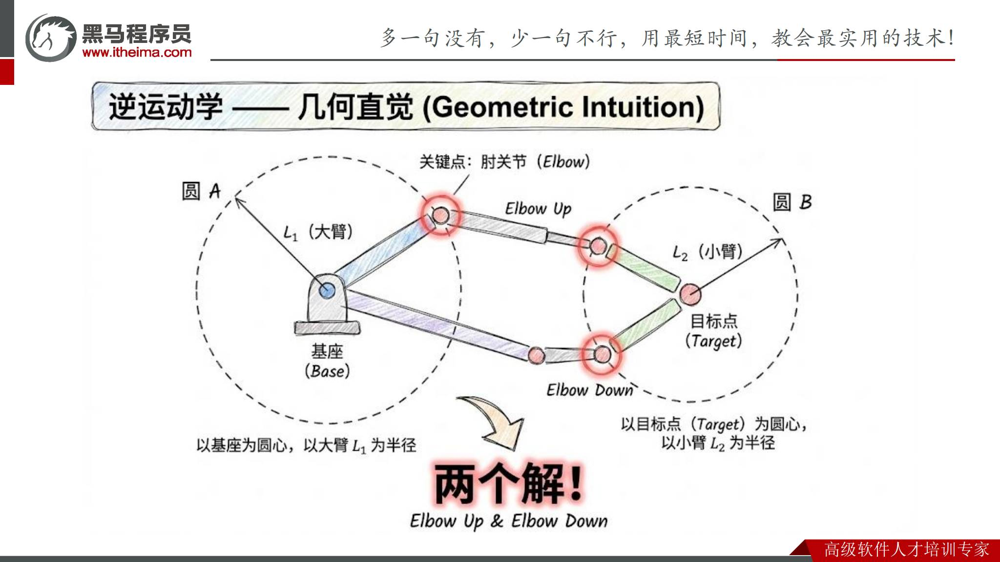

*原课件第50页：同一个目标位置可能对应两种肘部配置。*

沿用上一节的二维二连杆定义，目标是`(x, y)`。由余弦定理：

\[
c_2=\cos q_2=\frac{x^2+y^2-L_1^2-L_2^2}{2L_1L_2}.
\]

\[
q_2=\operatorname{atan2}(\pm\sqrt{1-c_2^2},c_2),\qquad
q_1=\operatorname{atan2}(y,x)-\operatorname{atan2}(L_2\sin q_2,L_1+L_2\cos q_2).
\]

**工程补充：**在`kinematics_2r.py`中继续添加下列函数。它返回候选解，不选实际运动路径：

```python
def ik_2r(x, y, l1=0.3, l2=0.2):
    if not all(math.isfinite(value) for value in (x, y, l1, l2)):
        raise ValueError('All inputs must be finite')
    if l1 <= 0.0 or l2 <= 0.0:
        raise ValueError('Link lengths must be positive')
    radius = math.hypot(x, y)
    tolerance = 1e-12 * max(l1, l2)
    if radius > l1 + l2 + tolerance:
        return []
    if radius < abs(l1 - l2) - tolerance:
        return []
    if radius == 0.0 and l1 == l2:
        raise ValueError('Infinitely many shoulder angles at this singular target')
    c2 = (x*x + y*y - l1*l1 - l2*l2) / (2.0*l1*l2)
    c2 = max(-1.0, min(1.0, c2))
    s2 = math.sqrt(max(0.0, 1.0 - c2*c2))
    signs = (1.0,) if s2 < 1e-10 else (1.0, -1.0)
    solutions = []
    for sign in signs:
        q2 = math.atan2(sign * s2, c2)
        q1 = math.atan2(y, x) - math.atan2(
            l2 * math.sin(q2), l1 + l2 * math.cos(q2))
        q1 = math.atan2(math.sin(q1), math.cos(q1))
        solutions.append((q1, q2))
    return solutions
```

先判断几何可达，再把接近边界时的浮点误差限制到有效区间；不能把明显不可达的目标强行截断成“有解”。忽略关节限制时，二维位置可达范围为：

\[
|L_1-L_2|\leq\sqrt{x^2+y^2}\leq L_1+L_2.
\]

本例`(0.3, 0.2)`通常有两组解，`(0.6, 0)`超出0.5米最大伸展距离，返回空列表。两杆等长并完全折叠到原点时，肩角不唯一，示例明确报告退化情况。

平面二连杆的位置雅可比行列式为`L1 * L2 * sin(q2)`，伸直或完全折叠时为零。**奇异不等于所有关节都物理锁死**，而是某些末端瞬时运动方向无法独立产生，逆速度计算可能不稳定；目标也可能恰好可达。

多解不代表每个解都能用于当前任务。还需检查关节限位、末端朝向、与当前姿态的连续性以及碰撞。第53页的角度只是图示，不应直接作为某台机械臂的关节指令。


## 19. 视觉到抓取的完整职责链

课件第54页将前面的内容汇成五个模块：摄像头、物品识别、坐标转换、抓取、硬件驱动。

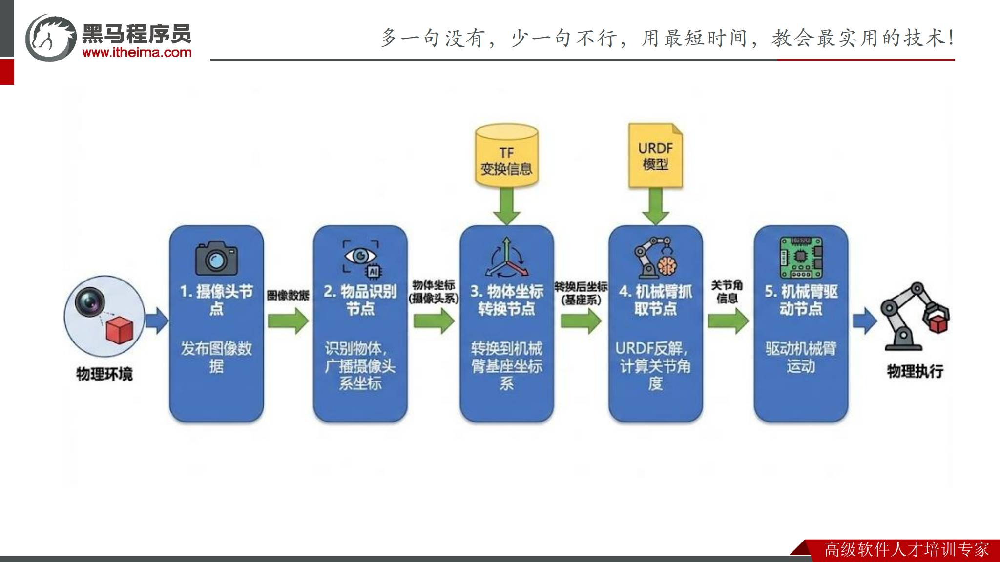

*原课件第54页：视觉数据经过识别、坐标转换和运动学处理，再交给机械臂驱动。*

| 模块 | 本阶段负责什么 | 需要交接的条件 |
|---|---|---|
| 摄像头节点 | 采集与发布图像 | 图像编码、尺寸、采集时间和参考帧 |
| 物品识别节点 | 目标检测与位置提取 | 有效性、像素位置；具备标定后才是物理位置 |
| 坐标转换节点 | 统一到机械臂基座参考系 | 米制位置、正确帧关系和时间 |
| 抓取/运动节点 | 根据模型与目标计算关节方案 | 位姿约束、限位与动作过程 |
| 机械臂驱动节点 | 按控制接口驱动设备并返回状态 | 关节顺序、单位、状态与故障反馈 |

**工程澄清：**课件“URDF反解”是概念简写，实际由求解器使用机器人模型求逆解。IK得到一组关节配置后，还要安排到达该配置的运动过程；不能把“终点有解”理解成“沿途不碰撞”。

一次抓取通常还包含接近、下降、夹取、抬升等阶段，工具参考帧和抓取姿态要与模型一致。这里按课件理解职责链，不假设已经完成真实设备的抓取程序。

本篇示例有意在数据层验证：颜色节点输出像素、TF示例使用已定位的米制点、二连杆例子验证几何计算。把三者接到真实机械臂前，必须补齐与设备相符的标定、模型和控制接口。


## 20. 按数据流核对结果

下面是对原课实验的**工程补充检查顺序**，用于定位问题发生在哪一层。

| 现象 | 对照本篇检查 |
|---|---|
| 红蓝颜色反了 | BGR/RGB顺序和`Image.encoding` |
| 向下移动但坐标解释为向上 | 图像v轴与物理坐标轴混用 |
| 红色目标偶尔漏掉 | 红色两段H阈值、S/V下限、曝光与白平衡 |
| 掩膜散点多或目标消失 | 先看原始Mask，再看核大小和面积过滤 |
| 中心落在两物体之间 | 是否对全图Mask求矩，是否需要逐轮廓处理 |
| 相机在Windows可用、Ubuntu不可用 | 虚拟机设备归属、设备节点、占用情况 |
| Topic可见却没有图像回调 | 话题名、类型、QoS与执行器 |
| TF查询失败 | 来源帧、目标帧、树是否连通及时间覆盖 |
| TF成功但位置离谱 | 是否把像素当米、变换方向或旋转符号是否错误 |
| 目标物理位置正确但机械臂姿态错误 | 模型零位、相对角、工具帧与度/弧度 |
| IK有解却不能执行 | 限位、碰撞、奇异性和运动路径 |

二连杆示例可用“逆解后再正解”核对，而不是只看角度似乎合理。在`kinematics_2r.py`末尾添加并用系统`python3`执行，它只依赖标准库：

```python
if __name__ == '__main__':
    goal = (0.3, 0.2)
    solutions = ik_2r(*goal)
    assert len(solutions) == 2
    for q1, q2 in solutions:
        x, y = fk_2r(q1, q2)
        assert math.hypot(x - goal[0], y - goal[1]) < 1e-9
    assert ik_2r(0.6, 0.0) == []
    assert len(ik_2r(0.5, 0.0)) == 1
    print('2R geometry checks passed')
```

这类数值检查验证数学模型内的一致性，不验证实际硬件参数。ROS部分按第9—11节逐层查看图像和位置消息；坐标部分用第13—14节已知点检查方向，再处理实际标定结果。

课件的完整学习链路是：**图像矩阵 → HSV分割 → 掩膜去噪 → 目标中心 → ROS节点协作 → 物理定位与坐标转换 → 机械臂运动学 → 驱动执行。**其中每一步都要交代数据含义，后一步才能正确使用前一步的结果。
